# Librerias

In [1]:
"""import optbinning
import ortools

print("OptBinning:", optbinning.__version__)
print("OR-Tools:", ortools.__version__)"""

'import optbinning\nimport ortools\n\nprint("OptBinning:", optbinning.__version__)\nprint("OR-Tools:", ortools.__version__)'

In [2]:
!pip install -r ../requirements.txt

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, date, timedelta
import seaborn as sns
from typing import Optional

import os
import pickle

from sklearn import preprocessing
import importlib

from optbinning import OptimalBinning, BinningProcess

#from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# Carga Data

In [4]:
df_data = pd.read_csv(
    "../data/02_intermediate/Base_preselected.csv",
    dtype={

    },
)

In [5]:
df_data.head()

,target,income,name_email_similarity,prev_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_4w,...,period,address_stability_ratio,digital_identity_score,velocity_ratio_6h_24h,velocity_ratio_24h_4w,device_trust_score,email_risk_score,credit_limit_income_ratio,credit_risk_limit_ratio,contact_consistency
0,0,0.3,0.986506,-1.0,40,0.006735,102.453711,AA,1059,6742.080561,...,2024-01-01,25.000000,1,1.668082,1.164471,1,0.067468,5000.000000,0.222,0
1,0,0.8,0.617426,-1.0,20,0.010095,-0.849551,AD,1658,5941.664859,...,2024-01-01,89.000000,2,1.605375,0.966943,1,6.886332,1875.000000,0.216,1
2,0,0.8,0.996707,9.0,40,0.012316,-1.490386,AB,1095,5992.555113,...,2024-01-01,1.555556,1,0.817157,0.913131,2,0.036223,250.000000,1.295,0
3,0,0.6,0.475100,11.0,30,0.006991,-1.863101,AB,3483,5970.336831,...,2024-01-01,1.272727,1,2.136382,1.131485,1,6.823701,333.333333,1.300,0
4,0,0.9,0.842307,-1.0,40,5.742626,47.152498,AA,2339,5940.734212,...,2024-01-01,29.000000,3,1.483498,0.862528,2,0.946159,222.222222,1.305,1


In [6]:
df_data.shape

(1000000, 35)

In [7]:
df_data.dtypes

target                                int64
income                              float64
name_email_similarity               float64
prev_address_months_count           float64
customer_age                          int64
days_since_request                  float64
intended_balcon_amount              float64
payment_type                         object
zip_count_4w                          int64
velocity_4w                         float64
bank_branch_count_8w                  int64
date_of_birth_distinct_emails_4w      int64
employment_status                    object
credit_risk_score                     int64
email_is_free                         int64
housing_status                       object
phone_mobile_valid                    int64
bank_months_count                   float64
has_other_cards                       int64
foreign_request                       int64
source                               object
session_length_in_minutes           float64
device_os                       

In [8]:
# Mostrar todas las filas
pd.set_option("display.max_rows", None)

# Mostrar todas las columnas
pd.set_option("display.max_columns", None)

# No truncar el ancho de la salida
pd.set_option("display.width", None)

# No truncar el contenido de las columnas
pd.set_option("display.max_colwidth", None)

In [9]:
# Quiero que se muestre todos los registros del dataframe y no esto "..."
df_data.isna().sum()

target                              0
income                              0
name_email_similarity               0
prev_address_months_count           0
customer_age                        0
days_since_request                  0
intended_balcon_amount              0
payment_type                        0
zip_count_4w                        0
velocity_4w                         0
bank_branch_count_8w                0
date_of_birth_distinct_emails_4w    0
employment_status                   0
credit_risk_score                   0
email_is_free                       0
housing_status                      0
phone_mobile_valid                  0
bank_months_count                   0
has_other_cards                     0
foreign_request                     0
source                              0
session_length_in_minutes           0
device_os                           0
device_distinct_emails_8w           0
device_fraud_count                  0
period                              0
address_stab

In [10]:
df_data.head()

,target,income,name_email_similarity,prev_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,employment_status,credit_risk_score,email_is_free,housing_status,phone_mobile_valid,bank_months_count,has_other_cards,foreign_request,source,session_length_in_minutes,device_os,device_distinct_emails_8w,device_fraud_count,period,address_stability_ratio,digital_identity_score,velocity_ratio_6h_24h,velocity_ratio_24h_4w,device_trust_score,email_risk_score,credit_limit_income_ratio,credit_risk_limit_ratio,contact_consistency
0,0,0.3,0.986506,-1.0,40,0.006735,102.453711,AA,1059,6742.080561,5,5,CB,163,1,BC,1,9.0,0,0,INTERNET,16.224843,linux,1,0,2024-01-01,25.000000,1,1.668082,1.164471,1,0.067468,5000.000000,0.222,0
1,0,0.8,0.617426,-1.0,20,0.010095,-0.849551,AD,1658,5941.664859,3,18,CA,154,1,BC,1,2.0,0,0,INTERNET,3.363854,other,1,0,2024-01-01,89.000000,2,1.605375,0.966943,1,6.886332,1875.000000,0.216,1
2,0,0.8,0.996707,9.0,40,0.012316,-1.490386,AB,1095,5992.555113,15,11,CA,89,1,BC,1,30.0,0,0,INTERNET,22.730559,windows,1,0,2024-01-01,1.555556,1,0.817157,0.913131,2,0.036223,250.000000,1.295,0
3,0,0.6,0.475100,11.0,30,0.006991,-1.863101,AB,3483,5970.336831,11,13,CA,90,1,BC,1,1.0,0,0,INTERNET,15.215816,linux,1,0,2024-01-01,1.272727,1,2.136382,1.131485,1,6.823701,333.333333,1.300,0
4,0,0.9,0.842307,-1.0,40,5.742626,47.152498,AA,2339,5940.734212,1,6,CA,91,0,BC,1,26.0,0,0,INTERNET,3.743048,other,1,0,2024-01-01,29.000000,3,1.483498,0.862528,2,0.946159,222.222222,1.305,1


# Split Data

In [30]:
# Quiero dividir df_data en train, test y oot. Train con period 2024-01-01 a 2024-06-30, test con period 2024-07-01 a 2024-07-31 y oot con period 2024-08-01 a 2024-08-31
train_data = df_data[(df_data['period'] >= '2024-01-01') & (df_data['period'] <= '2024-05-31')]
val_data = df_data[(df_data['period'] >= '2024-06-01') & (df_data['period'] <= '2024-06-30')]
test_data = df_data[(df_data['period'] >= '2024-07-01') & (df_data['period'] <= '2024-07-31')]
oot_data = df_data[(df_data['period'] >= '2024-08-01') & (df_data['period'] <= '2024-08-31')]

# Mostrar el tamaño de cada conjunto
print(f"Tamaño del conjunto de entrenamiento (train): {len(train_data)}")
print(f"Tamaño del conjunto de validación (val): {len(val_data)}")
print(f"Tamaño del conjunto de test: {len(test_data)}")
print(f"Tamaño del conjunto de oot: {len(oot_data)}")

Tamaño del conjunto de entrenamiento (train): 675666
Tamaño del conjunto de validación (val): 119323
Tamaño del conjunto de test: 108168
Tamaño del conjunto de oot: 96843


In [32]:
num_features = (
    df_data
    .select_dtypes(include=[np.number])
    .columns
    .drop("target")
    .tolist()
)

In [35]:
X_train = train_data[num_features].copy()
y_train = train_data["target"].copy()

X_val = val_data[num_features].copy()
y_val = val_data["target"].copy()

X_test = test_data[num_features].copy()
y_test = test_data["target"].copy()

X_oot = oot_data[num_features].copy()
y_oot = oot_data["target"].copy()

In [14]:
X_train.head()

,income,name_email_similarity,prev_address_months_count,customer_age,days_since_request,intended_balcon_amount,zip_count_4w,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,credit_risk_score,email_is_free,phone_mobile_valid,bank_months_count,has_other_cards,foreign_request,session_length_in_minutes,device_distinct_emails_8w,device_fraud_count,address_stability_ratio,digital_identity_score,velocity_ratio_6h_24h,velocity_ratio_24h_4w,device_trust_score,email_risk_score,credit_limit_income_ratio,credit_risk_limit_ratio,contact_consistency
0,0.3,0.986506,-1.0,40,0.006735,102.453711,1059,6742.080561,5,5,163,1,1,9.0,0,0,16.224843,1,0,25.000000,1,1.668082,1.164471,1,0.067468,5000.000000,0.222,0
1,0.8,0.617426,-1.0,20,0.010095,-0.849551,1658,5941.664859,3,18,154,1,1,2.0,0,0,3.363854,1,0,89.000000,2,1.605375,0.966943,1,6.886332,1875.000000,0.216,1
2,0.8,0.996707,9.0,40,0.012316,-1.490386,1095,5992.555113,15,11,89,1,1,30.0,0,0,22.730559,1,0,1.555556,1,0.817157,0.913131,2,0.036223,250.000000,1.295,0
3,0.6,0.475100,11.0,30,0.006991,-1.863101,3483,5970.336831,11,13,90,1,1,1.0,0,0,15.215816,1,0,1.272727,1,2.136382,1.131485,1,6.823701,333.333333,1.300,0
4,0.9,0.842307,-1.0,40,5.742626,47.152498,2339,5940.734212,1,6,91,0,1,26.0,0,0,3.743048,1,0,29.000000,3,1.483498,0.862528,2,0.946159,222.222222,1.305,1


# Balanceo de clases

## Undersampling

In [15]:
train_data.columns

Index(['target', 'income', 'name_email_similarity',
       'prev_address_months_count', 'customer_age', 'days_since_request',
       'intended_balcon_amount', 'payment_type', 'zip_count_4w', 'velocity_4w',
       'bank_branch_count_8w', 'date_of_birth_distinct_emails_4w',
       'employment_status', 'credit_risk_score', 'email_is_free',
       'housing_status', 'phone_mobile_valid', 'bank_months_count',
       'has_other_cards', 'foreign_request', 'source',
       'session_length_in_minutes', 'device_os', 'device_distinct_emails_8w',
       'device_fraud_count', 'period', 'address_stability_ratio',
       'digital_identity_score', 'velocity_ratio_6h_24h',
       'velocity_ratio_24h_4w', 'device_trust_score', 'email_risk_score',
       'credit_limit_income_ratio', 'credit_risk_limit_ratio',
       'contact_consistency'],
      dtype='object')

In [36]:
from imblearn.under_sampling import RandomUnderSampler

X_train_resampled_list = []
y_train_resampled_list = []

for periodo, group in train_data.groupby("period"):

    X_group = group[num_features].copy()
    y_group = group["target"].copy()

    rus = RandomUnderSampler(
        random_state=42
    )

    X_resampled, y_resampled = rus.fit_resample(
        X_group,
        y_group
    )

    X_train_resampled_list.append(X_resampled)
    y_train_resampled_list.append(y_resampled)

X_train_resampled = pd.concat(
    X_train_resampled_list,
    axis=0,
    ignore_index=True
)

y_train_resampled = pd.concat(
    y_train_resampled_list,
    axis=0,
    ignore_index=True
)

print("Distribución antes del undersampling:")
print(y_train.value_counts())

print("\nDistribución después del undersampling:")
print(y_train_resampled.value_counts())

print("\nTamaño de X_train_resampled:")
print(X_train_resampled.shape)

Distribución antes del undersampling:
target
0    668926
1      6740
Name: count, dtype: int64

Distribución después del undersampling:
target
0    6740
1    6740
Name: count, dtype: int64

Tamaño de X_train_resampled:
(13480, 28)


In [37]:
X_train_resampled.columns

Index(['income', 'name_email_similarity', 'prev_address_months_count',
       'customer_age', 'days_since_request', 'intended_balcon_amount',
       'zip_count_4w', 'velocity_4w', 'bank_branch_count_8w',
       'date_of_birth_distinct_emails_4w', 'credit_risk_score',
       'email_is_free', 'phone_mobile_valid', 'bank_months_count',
       'has_other_cards', 'foreign_request', 'session_length_in_minutes',
       'device_distinct_emails_8w', 'device_fraud_count',
       'address_stability_ratio', 'digital_identity_score',
       'velocity_ratio_6h_24h', 'velocity_ratio_24h_4w', 'device_trust_score',
       'email_risk_score', 'credit_limit_income_ratio',
       'credit_risk_limit_ratio', 'contact_consistency'],
      dtype='object')

In [38]:
# Eliminar period de todos los conjuntos
X_train_resampled = X_train_resampled.drop(
    columns=["period"],
    errors="ignore"
).copy()


X_test = X_test.drop(
    columns=["period"],
    errors="ignore"
).copy()

X_oot = X_oot.drop(
    columns=["period"],
    errors="ignore"
).copy()

# Evaluacion

In [18]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, accuracy_score

# 🔹 Función para visualizar la matriz de confusión y calcular métricas
def plot_confusion_matrix_heatmap(y_true, y_pred_proba, model_name='Modelo'):
    """
    Visualiza la matriz de confusión con un heatmap.
    Calcula correctamente AUC-ROC con probabilidades.
    """
    # Convertir probabilidades en clases con umbral 0.5
    y_pred = (y_pred_proba >= 0.5).astype(int)

    # Calcular la matriz de confusión
    conf_matrix = confusion_matrix(y_true, y_pred)

    # ✅ Calcular correctamente el AUC con probabilidades
    auc = roc_auc_score(y_true, y_pred_proba)  # 🔹 Usamos proba en lugar de 0/1

    # Calcular Accuracy
    accuracy = accuracy_score(y_true, y_pred)

    # Mostrar la matriz de confusión con un heatmap
    plt.figure(figsize=(8, 6))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', linewidths=0.5, square=True)
    plt.title(f'Matriz de Confusión - {model_name}\nAUC-ROC: {auc:.2f} | Accuracy: {accuracy:.2f}')
    plt.xlabel('Predicción')
    plt.ylabel('Actual')
    plt.xticks(ticks=[0.5, 1.5], labels=['Clase 0', 'Clase 1'])
    plt.yticks(ticks=[0.5, 1.5], labels=['Clase 0', 'Clase 1'])
    plt.show()

    # Imprimir reporte de clasificación
    print(f'\nReporte de Clasificación - {model_name}')
    print(classification_report(y_true, y_pred))
    print(f"AUC-ROC: {auc:.2f}")
    print(f"Accuracy: {accuracy:.2f}")

# Ejemplo de uso con múltiples modelos
# Suponiendo que tienes predicciones de varios modelos
# pred_model1, pred_model2, pred_model3 son las predicciones de tus modelos
# y_test es el conjunto de datos real

# Modelo 1
# plot_confusion_matrix_heatmap(y_test, pred1, model_name='Modelo 1 - XGBoost')

# Si tienes más modelos:
# plot_confusion_matrix_heatmap(y_test, pred_model2, model_name='Modelo 2 - RandomForest')
# plot_confusion_matrix_heatmap(y_test, pred_model3, model_name='Modelo 3 - Logistic Regression')


## Funcion Objetivo

In [ ]:
from bayes_opt import BayesianOptimization
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score
from sklearn.metrics import average_precision_score

# ============================================================
# Función objetivo para Bayesian Optimization
# ============================================================

def xgb_evaluate(
    max_depth,
    gamma,
    colsample_bytree,
    learning_rate,
    n_estimators,
    subsample,
    min_child_weight,
    reg_alpha,
    reg_lambda
):
    """
    Entrena XGBoost con los datos balanceados y evalúa el
    AUC-ROC sobre el conjunto de validación original.
    """

    params = {
        "objective": "binary:logistic",
        "eval_metric": "auc",

        "max_depth": int(round(max_depth)),
        "gamma": gamma,
        "colsample_bytree": colsample_bytree,
        "learning_rate": learning_rate,
        "n_estimators": int(round(n_estimators)),
        "subsample": subsample,
        "min_child_weight": min_child_weight,

        "reg_alpha": reg_alpha,
        "reg_lambda": reg_lambda,

        # No se coloca scale_pos_weight porque el train
        # ya fue balanceado mediante resampling.
        "random_state": 150718,
        "n_jobs": -1
    }

    model = XGBClassifier(**params)

    # Entrenamiento únicamente con el train balanceado
    model.fit(
        X_train_resampled,
        y_train_resampled
    )

    # Validación sobre datos no balanceados
    y_val_pred_proba = model.predict_proba(X_val)[:, 1]

    #return roc_auc_score(y_val, y_val_pred_proba)
    return average_precision_score(y_val, y_val_pred_proba)

## Espacio de busqueda

In [20]:
params_pbounds = {
    "max_depth": (3, 6),
    "gamma": (0, 10),
    "colsample_bytree": (0.5, 0.9),
    "learning_rate": (0.01, 0.1),
    "n_estimators": (100, 1000),
    "subsample": (0.6, 0.95),
    "min_child_weight": (5, 40),
    "reg_alpha": (0, 20),
    "reg_lambda": (1, 20)
}

## Optimizacion Bayesiana

In [39]:
xgb_bo = BayesianOptimization(
    f=xgb_evaluate,
    pbounds=params_pbounds,
    random_state=42,
    verbose=2
)

xgb_bo.maximize(
    init_points=10,
    n_iter=10
)

|   iter    |  target   | colsam... |   gamma   | learni... | max_depth | min_ch... | n_esti... | reg_alpha | reg_la... | subsample |
-------------------------------------------------------------------------------------------------------------------------------------
| 1         | 0.8664    | 0.6498    | 9.507     | 0.07588   | 4.796     | 10.46     | 240.4     | 1.162     | 17.46     | 0.8104    |
| 2         | 0.8685    | 0.7832    | 0.2058    | 0.09729   | 5.497     | 12.43     | 263.6     | 3.668     | 6.781     | 0.7837    |
| 3         | 0.8697    | 0.6728    | 2.912     | 0.06507   | 3.418     | 15.23     | 429.7     | 9.121     | 15.92     | 0.6699    |
| 4         | 0.8485    | 0.7057    | 5.924     | 0.01418   | 4.823     | 10.97     | 158.5     | 18.98     | 19.35     | 0.8829    |
| 5         | 0.8708    | 0.6218    | 0.9767    | 0.07158   | 4.32      | 9.271     | 545.7     | 0.6878    | 18.28     | 0.6906    |
| 6         | 0.8668    | 0.765     | 3.117     | 0.05681   | 

In [40]:
best_params = xgb_bo.max["params"].copy()

# Convertir solamente los parámetros que deben ser enteros
best_params["max_depth"] = int(round(best_params["max_depth"]))
best_params["n_estimators"] = int(round(best_params["n_estimators"]))

print("\nMejores parámetros:")
for parametro, valor in best_params.items():
    print(f"{parametro}: {valor}")


Mejores parámetros:
colsample_bytree: 0.6453186354407439
gamma: 1.788557947780104
learning_rate: 0.056900838643780094
max_depth: 3
min_child_weight: 31.847088049679023
n_estimators: 505
reg_alpha: 0.662794010374399
reg_lambda: 19.78042967070454
subsample: 0.6524406644687335


## Training

In [41]:
xgb_best = XGBClassifier(
    **best_params,
    objective="binary:logistic",
    eval_metric="auc",
    random_state=150718,
    n_jobs=-1
)

xgb_best.fit(
    X_train_resampled,
    y_train_resampled
)

print("Modelo XGBoost entrenado correctamente.")

Modelo XGBoost entrenado correctamente.


## Test Evaluation

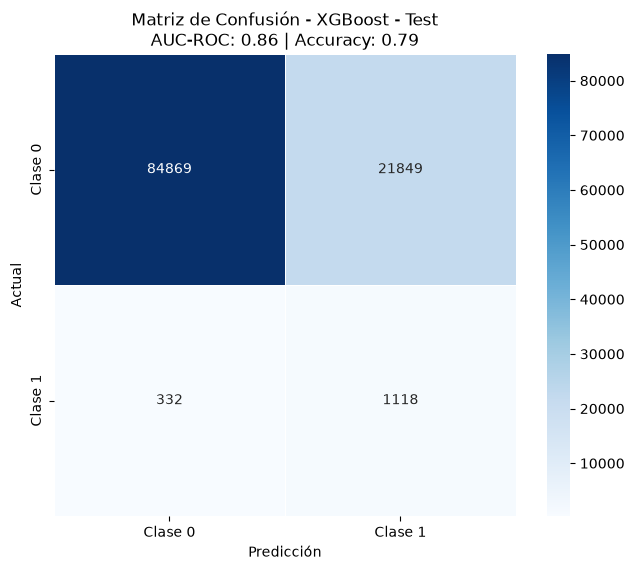


Reporte de Clasificación - XGBoost - Test
              precision    recall  f1-score   support

           0       1.00      0.80      0.88    106718
           1       0.05      0.77      0.09      1450

    accuracy                           0.79    108168
   macro avg       0.52      0.78      0.49    108168
weighted avg       0.98      0.79      0.87    108168

AUC-ROC: 0.86
Accuracy: 0.79


In [42]:
y_test_pred_proba = xgb_best.predict_proba(X_test)[:, 1]

plot_confusion_matrix_heatmap(
    y_true=y_test,
    y_pred_proba=y_test_pred_proba,
    model_name="XGBoost - Test"
)

## OOT Evaluation

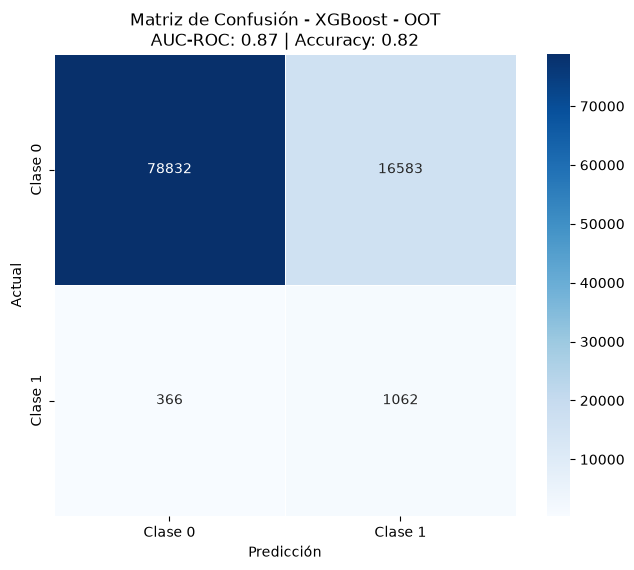


Reporte de Clasificación - XGBoost - OOT
              precision    recall  f1-score   support

           0       1.00      0.83      0.90     95415
           1       0.06      0.74      0.11      1428

    accuracy                           0.82     96843
   macro avg       0.53      0.78      0.51     96843
weighted avg       0.98      0.82      0.89     96843

AUC-ROC: 0.87
Accuracy: 0.82


In [43]:
y_oot_pred_proba = xgb_best.predict_proba(X_oot)[:, 1]

plot_confusion_matrix_heatmap(
    y_true=y_oot,
    y_pred_proba=y_oot_pred_proba,
    model_name="XGBoost - OOT"
)